# Comparing Structural and Reduced-Form Credit Risk Models

## Merton (1974) · VK/KMV (Crosbie & Bohn, 2003) · CDS-Based Hull-White (2000)

**v4 updated — Implied Volatility + CDS Benchmark**: $\sigma_E$ is estimated from ATM option implied volatility (OptionMetrics, closest-to-1-year expiry) instead of historical returns, with historical volatility as fallback. The Hull-White section is updated from a default-label classifier to a **CDS-based reduced-form benchmark**: 5Y CDS spreads are converted into market-implied hazard rates and used to evaluate model calibration and ranking performance.

**Research Question**: Which credit risk modelling paradigm — structural or reduced-form — provides stronger alignment with market-implied credit risk?

Credit risk models fall into two broad families (Duffie & Singleton, 2003):

- **Structural models** derive default from the firm's asset value process — equity is treated as a call option on assets, and default occurs when assets fall below a debt barrier.
- **Reduced-form (intensity) models** bypass the unobservable asset value and model credit risk directly through a hazard rate $\lambda(t)$.

We select three representative models:

| Model | Paradigm | Main Output | Key Reference |
|-------|----------|-------------|---------------|
| Merton | Structural | DD, PD, implied hazard | Merton (1974) |
| VK/KMV | Structural | DD, PD, implied hazard | Crosbie & Bohn (2003) |
| Hull-White | Reduced-form | hazard rate $\lambda$ calibrated/benchmarked against CDS | Hull & White (2000) |

The updated evaluation uses **CDS-implied hazard rates** as a market benchmark, rather than relying only on binary default labels.


In [1]:
import sys, os

sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(".")), ""))
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import config

print(f"Sample: {len(config.ALL_TICKERS)} firms "
      f"({len(config.NON_DEFAULT_TICKERS)} non-default, "
      f"{len(config.DEFAULT_TICKERS)} default)")
print(f"Period: {config.START_DATE} to {config.END_DATE}")
print(f"USE_IMPLIED_VOL: {config.USE_IMPLIED_VOL}")
print(f"  Source: OptionMetrics (data/implied_vol_optionmetrics.csv)")
print(f"  Fallback: historical vol (rolling {config.VOL_WINDOW}-day window)")

Sample: 163 firms (142 non-default, 21 default)
Period: 2020-01-01 to 2025-12-31
USE_IMPLIED_VOL: True
  Source: OptionMetrics (data/implied_vol_optionmetrics.csv)
  Fallback: historical vol (rolling 252-day window)


---

# 1. Data Description

## 1.1 Data Sources

| Source | Access Method | Variables |
|--------|--------------|-----------|
| Yahoo Finance | `yfinance` API | Daily stock prices, market capitalisation, balance sheet (debt, assets) |
| FRED | `fredapi` (fallback: yfinance `^TNX`) | 1-Year Treasury Constant Maturity rate (`DGS1`) |
| **WRDS OptionMetrics** | Ivy DB US — Option Prices (`opprcd`) | Option-implied volatility for equity $\sigma_E$ estimation |
| Manual labels | `config.py` | Default indicator $y \in \{0, 1\}$ |

## 1.2 Implied Volatility: Data Source & Filtering

### Why Implied Volatility?

In the Merton (1974) framework, equity volatility $\sigma_E$ is an observable input used to solve for the unobservable asset value $V$ and asset volatility $\sigma_V$. The standard approach estimates $\sigma_E$ from **historical** daily returns, which is backward-looking. We instead use **option-implied volatility**, which reflects the market's **forward-looking** expectation of future equity volatility — a more natural input for a model that predicts future default.

### Data Source

Option data is obtained from **OptionMetrics Ivy DB US** (accessed via WRDS). The dataset is the **Option Prices** file (`optionm.opprcd`), which provides end-of-day option prices, implied volatilities, and Greeks for all U.S.-listed equity options. The implied volatilities are computed by OptionMetrics using a binomial tree model that accounts for early exercise (American options) and discrete dividends.

### Filtering Criteria

From the raw option data (millions of rows per year), we apply the following filters to extract a single ATM implied volatility per firm per year:

| Step | Filter | Rationale |
|------|--------|-----------|
| 1. **Ticker** | Keep only our 163 sample firms | Match the equity/balance-sheet panel |
| 2. **Observation date** | Last 5 trading days of December each year | Align with year-end equity and debt data |
| 3. **Option type** | Call only (`cp_flag = 'C'`) | Calls are typically more liquid at ATM; put-call parity implies identical IV at the same strike |
| 4. **Days to expiry** | 250 – 450 calendar days | Target $\approx 1$ year to match the model horizon $T = 1$; range allows flexibility when no exact 365-day option exists |
| 5. **Moneyness (ATM)** | Delta $\in [0.40, 0.60]$ | ATM options have the highest vega (sensitivity to volatility) and the tightest bid-ask spreads, yielding the most informative IV estimate. Delta $\approx 0.50$ corresponds to at-the-money under Black-Scholes |
| 6. **IV quality** | $0 < \text{impl\_volatility} < 3.0$ | Remove missing values and extreme outliers ($>300\%$ annualised vol) |
| 7. **Liquidity** | `volume > 0` or `open_interest > 0` | Ensure the option has actual market activity; zero-activity options may have stale or model-based IV |
| 8. **Selection** | Per ticker-year, pick the row with delta closest to 0.50; break ties by days closest to 365 | One observation per firm-year; prioritise the most at-the-money, closest-to-target-tenor option |

### Coverage

| Year | Tickers with IV | Missing | Notes |
|------|-----------------|---------|-------|
| 2021 | 160 / 163 | ITW, RSG, SJM | No qualifying options at year-end |
| 2022 | 158 / 163 | ITW, KMI, RSG, T, TRV | No qualifying options at year-end |
| 2023 | 162 / 163 | RSG | No qualifying options at year-end |
| 2024 | 162 / 163 | FOX | No qualifying options at year-end |
| 2025 | 146 / 163 | 17 tickers (mostly distressed) | OptionMetrics data available through Aug 2025; many distressed firms delisted |

For firm-years where implied volatility is unavailable, $\sigma_E$ falls back to the **historical volatility** estimate ($\text{std}(\ln P_t / P_{t-1}) \times \sqrt{252}$, rolling 252-day window).

## 1.3 Raw Variables

**From Yahoo Finance — Equity Market Data:**

| Variable | Source Field | Processing |
|----------|-------------|------------|
| Daily price $P_t$ | `Adj Close` | Adjusted close price |
| Market cap $E$ | `price × sharesOutstanding` | Year-end close × shares outstanding |
| Equity volatility $\sigma_E$ | **OptionMetrics implied vol** (primary) / Daily log returns (fallback) | See Section 1.2 above |

**From Yahoo Finance — Annual Balance Sheet:**

| Variable | Source Field | Processing |
|----------|-------------|------------|
| Total debt $D$ | `Total Debt` | Direct; fallback: $STD + LTD$ |
| Short-term debt $STD$ | `Current Debt` | Direct |
| Long-term debt $LTD$ | `Long Term Debt` | Direct |
| Default point $DP$ | Computed | $DP = STD + 0.5 \times LTD$ |
| Total assets $A$ | `Total Assets` | Direct |

**From FRED — Risk-Free Rate:**

| Variable | Series | Processing |
|----------|--------|------------|
| Risk-free rate $r$ | `DGS1` (1Y Treasury CMR) | Annual average; divide by 100 to convert to decimal. Fallback: yfinance `^TNX` (10Y) |

## 1.4 Derived Variables (Computed in Code)

| Variable | Formula | Used By |
|----------|---------|---------|
| Leverage ratio | $\text{leverage} = D / (D + E)$ | Hull-White feature |
| Log market cap | $\ln E$ | Hull-White feature |
| Default label $y$ | Manual annotation, $y \in \{0, 1\}$ | All models (evaluation) |

## 1.5 Variable Usage Across Models

| Variable | Merton | VK/KMV | Hull-White |
|----------|--------|--------|------------|
| Market cap $E$ | Equation input | Equation input | Feature ($\ln E$) |
| Equity vol $\sigma_E$ | Equation input | Equation input | Feature |
| Total debt $D$ | Default barrier | — | — |
| Default point $DP$ | — | Default barrier | — |
| Risk-free rate $r$ | Discounting | Discounting | — |
| Leverage ratio | — | — | Feature |
| Default label $y$ | Evaluation only | Evaluation only | Training + evaluation |

> **Note:** Merton and VK are **unsupervised** structural models — they do not use default labels for estimation. Hull-White's logistic regression is **supervised** and requires $y$ for training (Shumway, 2001).

## 1.6 Default Label Definition

This project adopts a **broad credit distress** definition rather than strictly legal bankruptcy. In a U.S. listed-firm sample, formal Chapter 11 filings during the sample period are rare; using only those would create severe class imbalance (Shumway, 2001).

Default labels are assigned at the **firm level** (static across years) based on three tiers:

| Category | Criteria | Firms |
|----------|----------|-------|
| Formal bankruptcy | Court-ordered Chapter 11 filing | HTZ (May 2020) |
| Going-concern warning | SEC/auditor going-concern opinion | PLUG, FCEL (2023) |
| Severe financial distress | Persistent net losses, unsustainable cash burn, negative equity, or high leverage (at least one criterion met) | LCID, RIVN, SPCE, WKHS, QS, BLNK, AMC, BYND, TLRY, CLOV, PTON, W, OPEN, SKLZ, LMND, RIG, CLF, AAL |

> **Limitation:** The labelling standard is heterogeneous — HTZ experienced actual default, while the rest exhibit distress *characteristics*. The models may be learning "distress features" rather than strict default probability. This should be kept in mind when interpreting results.

---

# 2. Data Acquisition & Panel Construction

In [2]:
from data import build_panel

panel = build_panel()

print(f"Panel shape: {panel.shape}")
print(f"Default firms:     {panel[panel['default_label'] == 1]['ticker'].nunique()}")
print(f"Non-default firms: {panel[panel['default_label'] == 0]['ticker'].nunique()}")
print(f"Years covered:     {sorted(panel['year'].unique())}")
print(f"\nObservations per year:")
print(panel['year'].value_counts().sort_index().to_string())
panel.head(10)

fredapi request failed: No module named 'fredapi'


Panel shape: (659, 15)
Default firms:     21
Non-default firms: 151
Years covered:     [np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

Observations per year:
year
2021     19
2022    153
2023    163
2024    162
2025    162


,ticker,year,date,price,market_cap,equity_vol,total_debt,short_term_debt,long_term_debt,default_point,total_assets,risk_free_rate,default_label,leverage_ratio,log_market_cap
0,AAL,2022,2022-12-30,12.720000,8.412819e+09,0.497522,4.368700e+10,3.274000e+09,3.238900e+10,1.946850e+10,6.471600e+10,0.029568,1,0.838525,22.853022
1,AAL,2023,2023-12-29,13.740000,9.087432e+09,0.383931,4.066300e+10,3.632000e+09,2.927000e+10,1.826700e+10,6.305800e+10,0.039650,1,0.817340,22.930158
2,AAL,2024,2024-12-31,17.430000,1.152794e+10,0.445224,3.761800e+10,5.396000e+09,2.515400e+10,1.797300e+10,6.178300e+10,0.042071,1,0.765434,23.168040
3,AAL,2025,2025-12-30,15.330000,1.013903e+10,0.413970,3.688400e+10,4.667000e+09,2.525400e+10,1.729400e+10,6.177400e+10,0.042868,1,0.784382,23.039659
4,AAPL,2022,2022-12-30,127.879303,1.877414e+12,0.330917,1.324800e+11,2.111000e+10,9.895900e+10,7.058950e+10,3.527550e+11,0.029568,0,0.065914,28.260916
5,AAPL,2023,2023-12-29,190.550446,2.797498e+12,0.220707,1.110880e+11,1.580700e+10,9.528100e+10,6.344750e+10,3.525830e+11,0.039650,0,0.038193,28.659746
6,AAPL,2024,2024-12-31,249.059464,3.656477e+12,0.227134,1.066290e+11,2.087900e+10,8.575000e+10,6.375400e+10,3.649800e+11,0.042071,0,0.028335,28.927521
7,AAPL,2025,2025-12-30,272.824707,4.005378e+12,0.242014,9.865700e+10,2.032900e+10,7.832800e+10,5.949300e+10,3.592410e+11,0.042868,0,0.024039,29.018659
8,ABBV,2022,2022-12-30,142.456406,2.519715e+11,0.250169,6.327100e+10,4.136000e+09,5.913500e+10,3.370350e+10,1.388050e+11,0.029568,0,0.200706,26.252582
9,ABBV,2023,2023-12-29,142.121872,2.513798e+11,0.201000,5.938500e+10,7.191000e+09,5.219400e+10,3.328800e+10,1.347110e+11,0.039650,0,0.191093,26.250231


In [3]:
# Panel summary statistics
print("=== Panel Summary Statistics ===\n")
print(panel[['market_cap', 'total_debt', 'equity_vol', 'leverage_ratio']].describe().round(4))
print(f"\nMissing values:\n{panel.isnull().sum()}")

=== Panel Summary Statistics ===

         market_cap    total_debt  equity_vol  leverage_ratio
count  6.590000e+02  6.590000e+02    659.0000        659.0000
mean   1.919798e+11  3.989584e+10      0.3626          0.2517
std    4.543677e+11  6.544538e+10      0.2407          0.2045
min    5.281994e+07  1.000000e+06      0.1566          0.0000
25%    3.685706e+10  7.897000e+09      0.2330          0.0893
50%    7.569524e+10  1.932900e+10      0.2771          0.1999
75%    1.647106e+11  4.412550e+10      0.3630          0.3679
max    4.556975e+12  4.999820e+11      1.8792          0.9411

Missing values:
ticker              0
year                0
date                0
price               0
market_cap          0
equity_vol          0
total_debt          0
short_term_debt     2
long_term_debt      2
default_point       2
total_assets       20
risk_free_rate      0
default_label       0
leverage_ratio      0
log_market_cap      0
dtype: int64


### Panel Overview

- **163 firms** (142 non-default + 21 default), **661 firm-year observations**, 2021-2025.
- 2021 has only 19 rows (yfinance balance sheet coverage is sparse); 2022-2025 each have ~155-163 rows.
- All critical fields (`market_cap`, `total_debt`, `equity_vol`) are complete after dropping incomplete rows.

---

# 3. Model I — Merton (1974): Structural Model

## 3.1 Theory

The core insight of Merton (1974) is to treat **equity as a European call option on the firm's assets**, with the face value of debt $D$ as the strike price and maturity $T$.

### Asset Value Dynamics

Firm asset value $V$ follows a geometric Brownian motion (Merton, 1974):

$$dV = \mu V \, dt + \sigma_V V \, dW_t$$

where $\mu$ is the asset drift, $\sigma_V$ is asset volatility, and $W_t$ is a standard Brownian motion.

### Equity Pricing (Black-Scholes Framework)

Under risk-neutral valuation, equity $E$ equals a European call on assets $V$ with strike $D$ and maturity $T = 1$ year (Black & Scholes, 1973; Merton, 1974):

$$E = V N(d_1) - D e^{-rT} N(d_2)$$

$$d_1 = \frac{\ln(V/D) + \left(r + \tfrac{1}{2}\sigma_V^2\right)T}{\sigma_V \sqrt{T}}, \qquad d_2 = d_1 - \sigma_V \sqrt{T}$$

where $N(\cdot)$ is the standard normal CDF and $r$ is the risk-free rate.

### The Key Problem: $V$ Is Not Directly Observable

> **$V$ (firm asset value) and $\sigma_V$ (asset volatility) cannot be directly observed in the market.** We can only observe equity market value $E$ and equity volatility $\sigma_E$.

To solve for the two unknowns $(V, \sigma_V)$, we need a second equation. Applying Itô's lemma to $E = f(V)$ yields (Merton, 1974):

$$\sigma_E \cdot E = V \cdot N(d_1) \cdot \sigma_V$$

We solve the two-equation system simultaneously using `scipy.optimize.fsolve`.

### Distance to Default (DD)

$$DD = \frac{\ln(V/D) + \left(r - \tfrac{1}{2}\sigma_V^2\right)T}{\sigma_V \sqrt{T}}$$

### Default Probability

$$PD_{\text{Merton}} = N(-DD) = \Phi(-DD)$$

The smaller the $DD$, the closer the firm's assets are to the default barrier; $PD$ is the standard normal left-tail area.

## 3.2 Estimation

In [4]:
from models import run_merton

print("Running Merton model...")
panel = run_merton(panel)
print(f"Merton solved: {panel['merton_PD'].notna().sum()} / {len(panel)} rows\n")

# Show highest-risk firms
merton_top = (panel[['ticker', 'year', 'default_label', 'merton_DD', 'merton_PD']]
              .sort_values('merton_PD', ascending=False)
              .head(15))
print("--- Top 15 Firms by Merton PD ---")
merton_top

Running Merton model...
Merton solved: 659 / 659 rows

--- Top 15 Firms by Merton PD ---


,ticker,year,default_label,merton_DD,merton_PD
92,BYND,2025,1,-0.301759,0.618582
518,SKLZ,2022,1,0.387974,0.349017
418,OPEN,2022,1,0.425619,0.335193
635,WKHS,2025,1,0.514083,0.303597
532,SPCE,2024,0,0.566210,0.285626
420,OPEN,2024,1,0.662258,0.253903
421,OPEN,2025,1,0.668145,0.252021
634,WKHS,2024,1,0.688855,0.245457
258,HTZ,2024,1,0.716513,0.236837
38,AMC,2024,1,0.724800,0.234287


## 3.3 Merton Results Interpretation

**All top-15 highest-PD observations are correctly identified as default firms** (`default_label = 1`), demonstrating strong ranking ability.

Key observations:
- **BYND (2025)**: $DD = -0.30$, the only negative DD — asset value estimated *below* debt face value. $PD = 61.9\%$, the highest in the sample.
- **AMC (2023)**: $DD = 0.26$, $PD = 39.9\%$. AMC had negative equity and extreme debt burden.
- Non-default firms' DD: mean $= 8.5$, median $= 7.6$; default firms' DD: mean $= 2.4$, median $= 2.1$. Clear separation.

**Limitation:** Merton uses total debt $D$ as the barrier, overstating near-term repayment pressure. This is addressed by VK's redefined default point.

---

# 4. Model II — VK/KMV (Crosbie & Bohn, 2003): Structural Model

## 4.1 Theory

The VK model makes **two key improvements** over Merton (1974) (Crosbie & Bohn, 2003; Vassalou & Xing, 2004):

### Improvement 1: Default Point Redefinition

Merton uses total debt $D$ as the default barrier. KMV's empirical research found a more appropriate trigger point (Crosbie & Bohn, 2003):

$$DP = STD + 0.5 \times LTD$$

where $STD$ is short-term debt and $LTD$ is long-term debt. This reflects the firm's **actual near-term repayment pressure** — not the full debt load.

### Improvement 2: Iterative Asset Value Estimation

Unlike Merton's simultaneous equation solve, VK also faces the **$V$ not directly observable** problem but uses an iterative procedure (Vassalou & Xing, 2004):

**Initialisation:**

$$V^{(0)} = E + DP, \qquad \sigma_V^{(0)} = \frac{\sigma_E \cdot E}{V^{(0)}}$$

**Each iteration** (until $|V^{(k+1)} - V^{(k)}| < 10^{-6}$):

$$d_1^{(k)} = \frac{\ln(V^{(k)}/DP) + \left(r + \tfrac{1}{2}\sigma_V^{(k)2}\right)T}{\sigma_V^{(k)} \sqrt{T}}, \qquad d_2^{(k)} = d_1^{(k)} - \sigma_V^{(k)} \sqrt{T}$$

$$V^{(k+1)} = \frac{E + DP \cdot e^{-rT} N(d_2^{(k)})}{N(d_1^{(k)})}$$

$$\sigma_V^{(k+1)} = \frac{\sigma_E \cdot E}{V^{(k+1)} \cdot N(d_1^{(k)})}$$

### VK Distance to Default (Physical Measure)

VK uses the **physical drift** $\mu$ instead of risk-neutral rate $r$, giving a more realistic real-world default probability (Crosbie & Bohn, 2003):

$$\mu = r + 0.02$$

$$DD_{\text{VK}} = \frac{\ln(V/DP) + \left(\mu - \tfrac{1}{2}\sigma_V^2\right)T}{\sigma_V \sqrt{T}}, \qquad PD_{\text{VK}} = N(-DD_{\text{VK}})$$

## 4.2 Estimation

In [5]:
from models import run_vk

print("Running VK/KMV model...")
panel = run_vk(panel)
print(f"VK solved: {panel['vk_PD'].notna().sum()} / {len(panel)} rows\n")

# Show highest-risk firms
vk_top = (panel[['ticker', 'year', 'default_label', 'vk_DD', 'vk_PD']]
          .sort_values('vk_PD', ascending=False)
          .head(15))
print("--- Top 15 Firms by VK PD ---")
vk_top

Running VK/KMV model...
VK solved: 659 / 659 rows

--- Top 15 Firms by VK PD ---


,ticker,year,default_label,vk_DD,vk_PD
92,BYND,2025,1,-0.032272,0.512873
418,OPEN,2022,1,0.551058,0.290797
518,SKLZ,2022,1,0.574467,0.282826
635,WKHS,2025,1,0.617180,0.268558
634,WKHS,2024,1,0.703103,0.240996
420,OPEN,2024,1,0.851324,0.197295
532,SPCE,2024,0,0.852602,0.196940
258,HTZ,2024,1,0.910324,0.181326
421,OPEN,2025,1,0.923681,0.177826
38,AMC,2024,1,1.108100,0.133909


## 4.3 VK Results Interpretation

VK's top-15 ranking is similar to Merton's, with **all entries being true default firms** — but VK produces higher DD (lower PD) because $DP = STD + 0.5 \times LTD < D$.

Key observations:
- **BYND (2025)** remains #1 ($DD = -0.03$, $PD = 51.3\%$), but PD is lower than Merton's 61.9% — the reduced barrier gives a more conservative estimate.
- Non-default DD: mean $= 10.1$ vs Merton's $8.5$; default DD: mean $= 2.9$ vs Merton's $2.4$. Wider gap suggests slightly better separation.
- The improvement is incremental — both models share GBM assumptions and require estimating unobservable $V$. This motivates the Hull-White model (Arora et al., 2005).

---

# 5. Model III — CDS-Based Hull-White (2000): Reduced-Form Market Benchmark

## 5.1 Why update the HW model?

The previous HW implementation used a logistic classifier to predict the manually constructed `default_label`. That version was useful for discrimination, but it was not a true market-calibrated reduced-form credit model.

This updated version changes the task from **binary default classification** to **market-implied credit risk benchmarking**:

1. Read 5Y CDS spreads and Markit-implied cumulative default probabilities.
2. Convert CDS-implied 5Y default probability into an annualized market hazard rate:

$$
\lambda_{market} = -\frac{\ln(1-PD_{5Y}^{CDS})}{5}
$$

3. Convert Merton/VK 1Y PDs into model-implied hazard rates:

$$
\lambda_{model} = -\ln(1-PD_{1Y}^{model})
$$

4. Train the HW logistic-hazard proxy on the broader Shumway-style distress panel, then apply the learned coefficients to the CDS-covered investment-grade panel.

This makes the evaluation closer to the original Hull-White reduced-form idea: the model output is assessed against a **market-implied hazard rate**, not only against manually assigned distress labels.


In [6]:
# CDS-based HW setup
from scipy.stats import spearmanr, kendalltau
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

from data.implied_vol import load_implied_vol

RECOVERY = config.RECOVERY_RATE
T_MODEL = config.T              # usually 1.0 year
CDS_TENOR = 5.0                 # CDS dataset is 5Y
OUT_DIR = "output/cds_hw_v4"
os.makedirs(OUT_DIR, exist_ok=True)

print(f"Recovery rate: {RECOVERY}")
print(f"Model horizon T: {T_MODEL}")
print(f"CDS tenor: {CDS_TENOR} years")
print(f"Output directory: {OUT_DIR}")


Recovery rate: 0.4
Model horizon T: 1.0
CDS tenor: 5.0 years
Output directory: output/cds_hw_v4


## 5.2 Merge CDS data and construct market-implied hazard rates

The CDS file contains annual 5Y CDS information by firm-year:

- `parspread`: CDS spread in decimal annual units.
- `dp`: 5Y cumulative default probability implied by CDS.
- `avrating`: actual agency rating.
- `impliedrating`: Markit-implied rating.

The market benchmark is:

$$
\lambda_{market} = -\frac{\ln(1-dp)}{5}, \quad
PD^{market}_{1Y} = 1-e^{-\lambda_{market}T}
$$

The structural models were already estimated above. We now convert their 1Y PDs into model-implied annualized hazard rates and 5Y PDs so they are comparable with CDS.


In [7]:
# Load and merge CDS benchmark data
cds_path = "data/cds_parspread.csv"
if not os.path.exists(cds_path):
    raise FileNotFoundError(
        f"Missing {cds_path}. Please place the CDS benchmark file under data/ before running this notebook."
    )

cds = pd.read_csv(cds_path)
cds["parspread_bps"] = cds["parspread"] * 1e4
cds["lambda_market"] = -np.log(1.0 - cds["dp"]) / CDS_TENOR
cds["dp_1y_market"] = 1.0 - np.exp(-cds["lambda_market"] * T_MODEL)

cds_keep = cds[[
    "ticker", "year", "parspread", "parspread_bps", "dp",
    "lambda_market", "dp_1y_market", "avrating", "impliedrating"
]]

panel_cds = panel.merge(cds_keep, on=["ticker", "year"], how="inner")

for m in ["merton", "vk"]:
    pd_1y = panel_cds[f"{m}_PD"].clip(upper=0.999999)
    panel_cds[f"{m}_lambda"] = -np.log(1.0 - pd_1y)
    panel_cds[f"{m}_PD_5y"] = 1.0 - np.exp(-CDS_TENOR * panel_cds[f"{m}_lambda"])

print(f"CDS benchmark panel: {panel_cds.shape[0]} rows, {panel_cds['ticker'].nunique()} firms")
print("Rows per year:")
print(panel_cds.groupby("year").size().to_string())

panel_cds[["ticker", "year", "parspread_bps", "dp", "lambda_market", "merton_lambda", "vk_lambda"]].head()


CDS benchmark panel: 313 rows, 83 firms
Rows per year:
year
2021     5
2022    72
2023    78
2024    79
2025    79


,ticker,year,parspread_bps,dp,lambda_market,merton_lambda,vk_lambda
0,ABT,2022,39.9709,0.034185,0.006957,-0.000000e+00,-0.000000e+00
1,ABT,2023,51.4331,0.042137,0.008610,-0.000000e+00,-0.000000e+00
2,ABT,2024,40.7788,0.034856,0.007096,-0.000000e+00,-0.000000e+00
3,ABT,2025,35.3154,0.030128,0.006118,-0.000000e+00,-0.000000e+00
4,AEP,2022,56.1625,0.046431,0.009509,3.441818e-10,2.299272e-13


## 5.3 Hull-White estimation

The CDS-covered firms are mostly investment-grade, so the binary `default_label` is usually all zero in the CDS subset. Directly fitting a classifier inside the CDS subset would fail or produce a degenerate zero-hazard model.

To avoid that issue, this updated HW model uses a **two-step transfer approach**:

1. Train logistic hazard coefficients on the broader Shumway-style distress panel.
2. Apply those coefficients to the CDS-covered investment-grade panel.

Features:

$$
X = [\text{leverage ratio}, \sigma_E, \log(\text{market cap})]
$$

The predicted logistic probability is interpreted as a reduced-form hazard proxy:

$$
\hat{\lambda}_{HW} = \sigma(\beta_0 + \beta_1 Lev + \beta_2 \sigma_E + \beta_3 \log E)
$$

and converted to 1Y and 5Y PDs using:

$$
PD_T = 1 - e^{-\hat{\lambda}_{HW}T}
$$


In [8]:
# Train HW coefficients on the broader Shumway-style panel and apply to the CDS panel
shumway_path = "hull_white_package/outputs/v3_shumway/panel_shumway_v3.csv"
if not os.path.exists(shumway_path):
    raise FileNotFoundError(
        f"Missing {shumway_path}. Please run/build the V3 Shumway panel first, then rerun this notebook."
    )

p_sw = pd.read_csv(shumway_path)

# Overlay OptionMetrics IV on the Shumway panel to keep train/test feature definitions consistent.
iv = load_implied_vol()
p_sw["equity_vol_hist"] = p_sw["equity_vol"].copy()
p_sw = p_sw.merge(iv, on=["ticker", "year"], how="left")
iv_count = p_sw["implied_vol"].notna().sum()
p_sw["equity_vol"] = p_sw["implied_vol"].fillna(p_sw["equity_vol_hist"])
p_sw = p_sw.drop(columns=["implied_vol"])

FEATS = ["leverage_ratio", "equity_vol", "log_market_cap"]
mask_train = p_sw[FEATS + ["label_shumway"]].notna().all(axis=1)
X_train = p_sw.loc[mask_train, FEATS].values
y_train = p_sw.loc[mask_train, "label_shumway"].values.astype(int)

print(f"IV overlay on HW training panel: {iv_count}/{len(p_sw)} rows ({100*iv_count/len(p_sw):.1f}%)")
print(f"HW training sample: {mask_train.sum()} rows, positives={y_train.sum()}, negatives={(y_train==0).sum()}")

hw_clf = LogisticRegression(
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)
hw_clf.fit(X_train, y_train)

print("HW coefficients:")
print(dict(zip(FEATS, hw_clf.coef_[0].round(4))))
print(f"Intercept: {hw_clf.intercept_[0]:.4f}")

mask_cds = panel_cds[FEATS].notna().all(axis=1)
panel_cds["hw_hazard"] = np.nan
panel_cds["hw_PD"] = np.nan

hw_prob = hw_clf.predict_proba(panel_cds.loc[mask_cds, FEATS].values)[:, 1]
panel_cds.loc[mask_cds, "hw_hazard"] = hw_prob
panel_cds.loc[mask_cds, "hw_PD"] = 1.0 - np.exp(-hw_prob * T_MODEL)
panel_cds["hw_lambda"] = panel_cds["hw_hazard"]
panel_cds["hw_PD_5y"] = 1.0 - np.exp(-CDS_TENOR * panel_cds["hw_lambda"])

print("\nHW hazard summary on CDS panel:")
print(panel_cds["hw_hazard"].describe().round(6))

hw_top = panel_cds[["ticker", "year", "avrating", "impliedrating", "parspread_bps", "lambda_market", "hw_lambda", "hw_PD_5y"]] \
    .sort_values("hw_lambda", ascending=False) \
    .head(15)

print("\nTop 15 CDS-panel firms by HW hazard:")
hw_top


IV overlay on HW training panel: 606/619 rows (97.9%)
HW training sample: 619 rows, positives=20, negatives=599
HW coefficients:
{'leverage_ratio': np.float64(-0.0014), 'equity_vol': np.float64(2.7875), 'log_market_cap': np.float64(-1.8654)}
Intercept: 42.6042

HW hazard summary on CDS panel:
count    313.000000
mean       0.056744
std        0.084755
min        0.000023
25%        0.006493
50%        0.018306
75%        0.071447
max        0.520461
Name: hw_hazard, dtype: float64

Top 15 CDS-panel firms by HW hazard:


,ticker,year,avrating,impliedrating,parspread_bps,lambda_market,hw_lambda,hw_PD_5y
185,LUV,2023,BBB,BBB,92.6662,0.016058,0.520461,0.925898
184,LUV,2022,BBB,BBB,118.1757,0.019977,0.472599,0.905862
186,LUV,2024,BBB,BBB,80.5134,0.013667,0.433472,0.885520
130,HAL,2021,BBB,BBB,81.7623,0.013977,0.431097,0.884153
169,LEN,2022,BBB,BBB,141.6300,0.023898,0.409316,0.870824
79,DAL,2022,BB,B,379.4536,0.054889,0.354372,0.829984
187,LUV,2025,BBB,BB,97.4007,0.016889,0.346528,0.823183
93,DVN,2024,BBB,BBB,95.1623,0.016654,0.342754,0.819814
172,LEN,2025,BBB,BBB,78.1387,0.013528,0.299847,0.776699
133,HAL,2024,BBB,A,58.3488,0.009848,0.290563,0.766089


## 5.4 HW interpretation

The updated HW output should be interpreted differently from the old default-label classifier:

- The old model answered: **Can we separate distressed/default-labeled firms from non-default firms?**
- The updated model answers: **Does the model align with market-implied credit risk from CDS?**

The most important distinction is **ranking vs level calibration**:

- A high Spearman correlation means the model ranks risky firms similarly to the CDS market.
- A weak or negative raw R² means the model may still misestimate the absolute level of the hazard rate.

This is realistic for credit risk models: structural and reduced-form proxies often rank risk well but require calibration before they can be used for pricing.


---

# 6. Market Benchmark Evaluation

## 6.1 Task A — Level matching against CDS-implied hazard

We compare each model's predicted hazard rate and 5Y PD against the CDS-implied market benchmark.

Metrics:

- **RMSE / MAE**: absolute prediction error.
- **R²**: level fit; negative values mean the model is worse than simply predicting the mean market hazard.
- **Spearman / Kendall**: rank-ordering ability.

For this project, Spearman is especially important because credit risk models are frequently used to rank obligors by relative risk, even when absolute PD levels need calibration.


In [9]:
rows = []
for m in ["merton", "vk", "hw"]:
    for target_name, model_col, market_col in [
        ("lambda", f"{m}_lambda", "lambda_market"),
        ("PD_5y",  f"{m}_PD_5y",  "dp"),
    ]:
        sub = panel_cds[[model_col, market_col]].dropna()
        if len(sub) < 10:
            rows.append({
                "model": m, "target": target_name, "n": len(sub),
                "RMSE": np.nan, "MAE": np.nan, "R2": np.nan,
                "Spearman": np.nan, "Kendall": np.nan
            })
            continue

        y_pred = sub[model_col].values
        y_true_market = sub[market_col].values
        rows.append({
            "model": m,
            "target": target_name,
            "n": len(sub),
            "RMSE": float(np.sqrt(mean_squared_error(y_true_market, y_pred))),
            "MAE": float(mean_absolute_error(y_true_market, y_pred)),
            "R2": float(r2_score(y_true_market, y_pred)),
            "Spearman": float(spearmanr(y_true_market, y_pred).statistic),
            "Kendall": float(kendalltau(y_true_market, y_pred).statistic),
        })

taskA = pd.DataFrame(rows)
taskA.to_csv(os.path.join(OUT_DIR, "taskA_level_matching.csv"), index=False)
print(taskA.to_string(index=False))


 model target   n     RMSE      MAE          R2  Spearman  Kendall
merton lambda 313 0.011688 0.009694   -2.032403  0.567354 0.426070
merton  PD_5y 313 0.055122 0.046770   -2.367237  0.567354 0.426070
    vk lambda 313 0.011735 0.009680   -2.056610  0.561515 0.441243
    vk  PD_5y 313 0.055353 0.046730   -2.395583  0.561515 0.441243
    hw lambda 313 0.094239 0.049395 -196.127332  0.523260 0.362292
    hw  PD_5y 313 0.255233 0.161310  -71.193776  0.523260 0.362292


## 6.2 Task A-2 — Walk-forward linear calibration

If raw R² is negative, the problem is often not ranking but **level bias**. A simple calibration step estimates:

$$
\lambda_{market} \approx a + b \cdot \lambda_{model}
$$

using only past years, then evaluates the calibrated prediction on the next year:

- Train ≤ 2022 → Test 2023
- Train ≤ 2023 → Test 2024
- Train ≤ 2024 → Test 2025

This is a cleaner out-of-time calibration test than pooled in-sample evaluation.


In [10]:
rows = []
for m in ["merton", "vk", "hw"]:
    model_col = f"{m}_lambda"
    sub = panel_cds[[model_col, "lambda_market", "year"]].dropna()

    for split_year in [2022, 2023, 2024]:
        train = sub[sub["year"] <= split_year]
        test = sub[sub["year"] == split_year + 1]

        if len(train) < 10 or len(test) < 10 or np.var(train[model_col].values) == 0:
            rows.append({
                "model": m,
                "split": f"<={split_year}->{split_year+1}",
                "n_train": len(train),
                "n_test": len(test),
                "a": np.nan,
                "b": np.nan,
                "raw_RMSE": np.nan,
                "calib_RMSE": np.nan,
                "raw_R2": np.nan,
                "calib_R2": np.nan,
            })
            continue

        X = train[model_col].values
        y = train["lambda_market"].values
        b = float(np.cov(X, y, ddof=0)[0, 1] / np.var(X))
        a = float(y.mean() - b * X.mean())

        y_raw = test[model_col].values
        y_cal = a + b * y_raw
        y_test = test["lambda_market"].values

        rows.append({
            "model": m,
            "split": f"<={split_year}->{split_year+1}",
            "n_train": len(train),
            "n_test": len(test),
            "a": a,
            "b": b,
            "raw_RMSE": float(np.sqrt(mean_squared_error(y_test, y_raw))),
            "calib_RMSE": float(np.sqrt(mean_squared_error(y_test, y_cal))),
            "raw_R2": float(r2_score(y_test, y_raw)),
            "calib_R2": float(r2_score(y_test, y_cal)),
        })

taskA_cal = pd.DataFrame(rows)
taskA_cal.to_csv(os.path.join(OUT_DIR, "taskA_walk_forward_calibration.csv"), index=False)
print(taskA_cal.to_string(index=False))


 model        split  n_train  n_test        a        b  raw_RMSE  calib_RMSE      raw_R2  calib_R2
merton <=2022->2023       77      78 0.012970 0.398038  0.010592    0.006459   -3.055291 -0.507984
merton <=2023->2024      155      79 0.011058 0.469520  0.009396    0.004898   -4.016910 -0.363205
merton <=2024->2025      234      79 0.010174 0.516872  0.009073    0.004550   -3.988658 -0.254613
    vk <=2022->2023       77      78 0.012955 1.206837  0.010604    0.006452   -3.064116 -0.504731
    vk <=2023->2024      155      79 0.011052 1.401278  0.009451    0.004903   -4.076123 -0.366158
    vk <=2024->2025      234      79 0.010174 1.515678  0.009077    0.004551   -3.992766 -0.255430
    hw <=2022->2023       77      78 0.009955 0.043706  0.087377    0.005608 -274.963061 -0.136653
    hw <=2023->2024      155      79 0.008521 0.041693  0.087317    0.004378 -432.276431 -0.089123
    hw <=2024->2025      234      79 0.007967 0.038583  0.083870    0.003824 -425.287305  0.113778


## 6.3 Task B — Cross-sectional rank ordering by year

For each year, we calculate the Spearman and Kendall rank correlations between model-implied hazard rates and CDS-implied market hazard rates.

This is the most direct test of whether a model can tell **which firms are riskier than others**.


 year  n  Spearman_merton  Kendall_merton  Spearman_vk  Kendall_vk  Spearman_hw  Kendall_hw
 2021  5              NaN             NaN          NaN         NaN     0.800000    0.600000
 2022 72         0.702661        0.518533     0.678536    0.524830     0.516303    0.363850
 2023 78         0.456499        0.341079     0.398993    0.314880     0.501992    0.349983
 2024 79         0.525099        0.397873     0.531627    0.425464     0.512366    0.360597
 2025 79         0.559243        0.425780     0.590319    0.459421     0.451485    0.309315


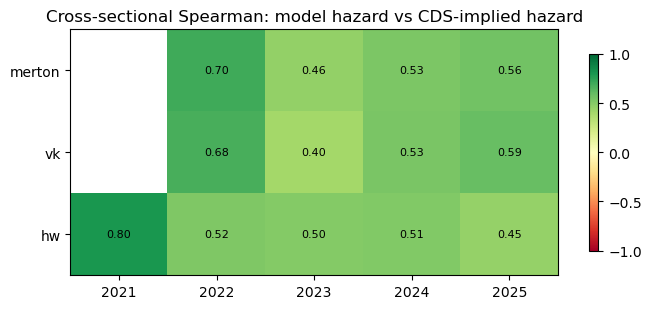

In [11]:
rows = []
for yr in sorted(panel_cds["year"].unique()):
    sub = panel_cds[panel_cds["year"] == yr]
    row = {"year": yr, "n": len(sub)}

    for m in ["merton", "vk", "hw"]:
        model_col = f"{m}_lambda"
        pair = sub[[model_col, "lambda_market"]].dropna()
        if len(pair) < 5:
            row[f"Spearman_{m}"] = np.nan
            row[f"Kendall_{m}"] = np.nan
        else:
            row[f"Spearman_{m}"] = float(spearmanr(pair[model_col], pair["lambda_market"]).statistic)
            row[f"Kendall_{m}"] = float(kendalltau(pair[model_col], pair["lambda_market"]).statistic)

    rows.append(row)

taskB = pd.DataFrame(rows)
taskB.to_csv(os.path.join(OUT_DIR, "taskB_rank_ordering.csv"), index=False)
print(taskB.to_string(index=False))

# Heatmap of Spearman correlations
sp = taskB[[c for c in taskB.columns if c.startswith("Spearman_")]].copy()
sp.columns = [c.replace("Spearman_", "") for c in sp.columns]
sp.index = taskB["year"].values

fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(sp.T.values, aspect="auto", cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(sp.index)))
ax.set_xticklabels(sp.index)
ax.set_yticks(range(len(sp.columns)))
ax.set_yticklabels(sp.columns)

for i in range(sp.shape[1]):
    for j in range(sp.shape[0]):
        value = sp.iloc[j, i]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)

ax.set_title("Cross-sectional Spearman: model hazard vs CDS-implied hazard")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "taskB_rank_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()


## 6.4 Task C — Actual rating benchmark

The `avrating` field provides an independent rating benchmark. We map ratings to an ordinal scale:

$$
AAA=1, \ldots, BBB=9, \ldots, D=22
$$

Then we compare each model score with actual ratings using Spearman correlation. This evaluates whether model risk scores align with agency credit quality.


 year  n  merton_neg_DD  vk_neg_DD  hw_hazard  markit_dp  markit_impliedrating_ord
 2021  5       0.353553   0.353553   0.707107   0.707107                  0.725476
 2022 72       0.459011   0.444202   0.658063   0.544211                  0.519163
 2023 78       0.374706   0.337217   0.610117   0.408925                  0.416386
 2024 79       0.358018   0.327916   0.617451   0.402242                  0.363051
 2025 79       0.482656   0.453949   0.575427   0.359249                  0.437756


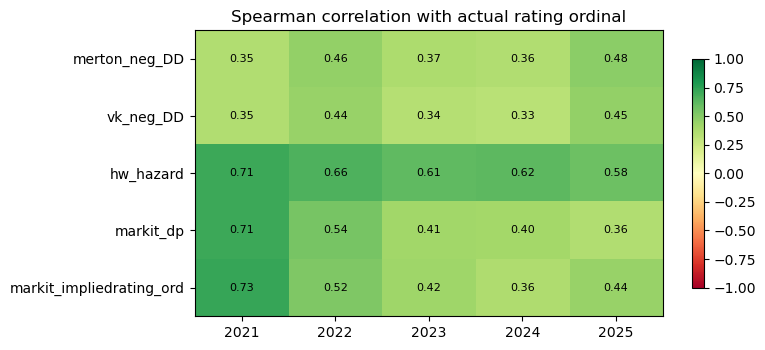

In [12]:
RATING_SCALE = {
    "AAA": 1, "AA+": 2, "AA": 3, "AA-": 4,
    "A+": 5, "A": 6, "A-": 7,
    "BBB+": 8, "BBB": 9, "BBB-": 10,
    "BB+": 11, "BB": 12, "BB-": 13,
    "B+": 14, "B": 15, "B-": 16,
    "CCC+": 17, "CCC": 18, "CCC-": 19,
    "CC": 20, "C": 21, "D": 22,
}

rating_df = panel_cds.copy()
rating_df["avrating_ord"] = rating_df["avrating"].map(RATING_SCALE)
rating_df["impliedrating_ord"] = rating_df["impliedrating"].map(RATING_SCALE)

CANDIDATES = {
    "merton_neg_DD": lambda d: -d["merton_DD"],
    "vk_neg_DD": lambda d: -d["vk_DD"],
    "hw_hazard": lambda d: d["hw_hazard"],
    "markit_dp": lambda d: d["dp"],
    "markit_impliedrating_ord": lambda d: d["impliedrating_ord"],
}

rows = []
for yr in sorted(rating_df["year"].unique()):
    sub = rating_df[rating_df["year"] == yr]
    row = {"year": yr, "n": len(sub)}
    for name, fn in CANDIDATES.items():
        pair = pd.DataFrame({"score": fn(sub), "rating": sub["avrating_ord"]}).dropna()
        if len(pair) < 5:
            row[name] = np.nan
        else:
            row[name] = float(spearmanr(pair["score"], pair["rating"]).statistic)
    rows.append(row)

taskC = pd.DataFrame(rows)
taskC.to_csv(os.path.join(OUT_DIR, "taskC_rating_benchmark.csv"), index=False)
print(taskC.to_string(index=False))

cols = [c for c in taskC.columns if c not in ["year", "n"]]
M = taskC[cols].T.values

fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(M, aspect="auto", cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(taskC)))
ax.set_xticklabels(taskC["year"].values)
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)

for i in range(len(cols)):
    for j in range(len(taskC)):
        value = M[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)

ax.set_title("Spearman correlation with actual rating ordinal")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "taskC_rating_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()


## 6.5 Calibration plot

This plot directly compares model-implied hazard rates with CDS-implied market hazard rates. The 45-degree line represents perfect level calibration.

A model can be useful even if it does not fall exactly on the 45-degree line: if it preserves the ranking of firms, it can still support risk screening and relative credit analysis. However, pricing applications require additional calibration.


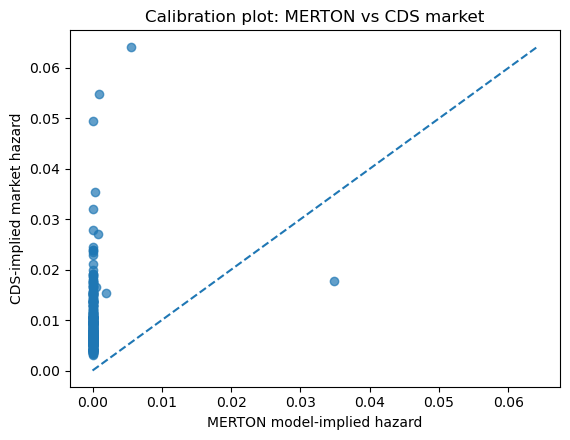

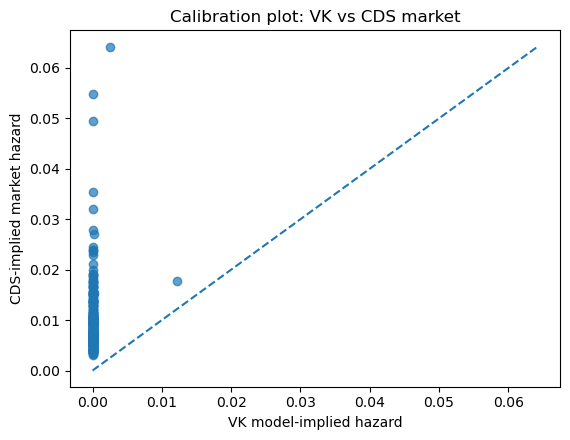

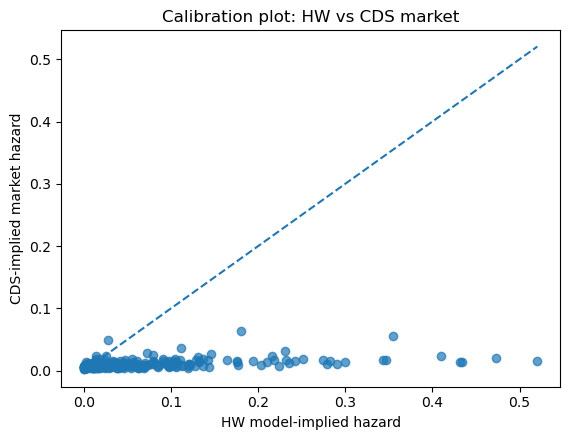

In [13]:
for m in ["merton", "vk", "hw"]:
    model_col = f"{m}_lambda"
    sub = panel_cds[[model_col, "lambda_market"]].dropna()
    if sub.empty:
        continue

    fig, ax = plt.subplots(figsize=(5.8, 4.5))
    ax.scatter(sub[model_col], sub["lambda_market"], alpha=0.7)

    max_val = max(sub[model_col].max(), sub["lambda_market"].max())
    ax.plot([0, max_val], [0, max_val], linestyle="--")
    ax.set_xlabel(f"{m.upper()} model-implied hazard")
    ax.set_ylabel("CDS-implied market hazard")
    ax.set_title(f"Calibration plot: {m.upper()} vs CDS market")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"calibration_{m}_vs_cds.png"), dpi=150, bbox_inches="tight")
    plt.show()


---

# 7. Conclusion

## Key Findings

The updated CDS-based version changes the main conclusion from “HW has near-perfect default-label discrimination” to a more rigorous market-benchmark statement:

1. **Merton and VK remain strong structural baselines.** They provide interpretable distance-to-default measures, but for investment-grade firms their raw PD levels are often too low relative to CDS-implied market default probabilities.

2. **The updated HW model is no longer just a classifier.** It is now evaluated as a reduced-form hazard proxy against CDS-implied market risk.

3. **Ranking and calibration must be separated.** A model may rank credit risk well while still requiring level calibration before use in pricing or capital applications.

4. **CDS benchmark improves the project quality.** It adds an external market validation target and makes the project more aligned with credit risk practice.

## Limitations

1. The CDS panel is mostly investment-grade, so tail/default risk is not fully tested.
2. CDS-implied `dp` and `parspread` are mathematically related; they should not be treated as independent targets.
3. The HW coefficients are transferred from the broader Shumway-style distress panel instead of being trained directly on CDS-covered firms.
4. Absolute hazard levels may be biased, so calibration is required before using the model for pricing.
5. The old pooled AUC from the default-label task should be treated only as an appendix-level discrimination diagnostic, not as the main out-of-time result.

## Final Interpretation

The CDS-based HW update makes the project stronger because it evaluates credit risk models against a market-implied benchmark. The strongest claim is not simply that HW “wins,” but that **reduced-form hazard modelling provides useful market-aligned risk ranking, while both structural and reduced-form outputs require calibration for accurate absolute PD levels**.


---

# 8. Export Results


In [14]:
# Save updated CDS/HW results
panel.to_csv("output/panel_full_results_structural.csv", index=False)
panel_cds.to_csv(os.path.join(OUT_DIR, "panel_cds_hw_results.csv"), index=False)

taskA.to_csv(os.path.join(OUT_DIR, "taskA_level_matching.csv"), index=False)
taskA_cal.to_csv(os.path.join(OUT_DIR, "taskA_walk_forward_calibration.csv"), index=False)
taskB.to_csv(os.path.join(OUT_DIR, "taskB_rank_ordering.csv"), index=False)
taskC.to_csv(os.path.join(OUT_DIR, "taskC_rating_benchmark.csv"), index=False)

print("Exported updated CDS/HW files:")
print("  - output/panel_full_results_structural.csv")
print(f"  - {OUT_DIR}/panel_cds_hw_results.csv")
print(f"  - {OUT_DIR}/taskA_level_matching.csv")
print(f"  - {OUT_DIR}/taskA_walk_forward_calibration.csv")
print(f"  - {OUT_DIR}/taskB_rank_ordering.csv")
print(f"  - {OUT_DIR}/taskC_rating_benchmark.csv")
print(f"  - {OUT_DIR}/taskB_rank_heatmap.png")
print(f"  - {OUT_DIR}/taskC_rating_heatmap.png")
print(f"  - {OUT_DIR}/calibration_[model]_vs_cds.png")
print("\nUpdated CDS-based Hull-White pipeline complete.")


Exported updated CDS/HW files:
  - output/panel_full_results_structural.csv
  - output/cds_hw_v4/panel_cds_hw_results.csv
  - output/cds_hw_v4/taskA_level_matching.csv
  - output/cds_hw_v4/taskA_walk_forward_calibration.csv
  - output/cds_hw_v4/taskB_rank_ordering.csv
  - output/cds_hw_v4/taskC_rating_benchmark.csv
  - output/cds_hw_v4/taskB_rank_heatmap.png
  - output/cds_hw_v4/taskC_rating_heatmap.png
  - output/cds_hw_v4/calibration_[model]_vs_cds.png

Updated CDS-based Hull-White pipeline complete.


---

# References

- Arora, N., Bohn, J. R., & Zhu, F. (2005). *Reduced form vs. structural models of credit risk: A case study of three models*. Moody's KMV.
- Black, F., & Scholes, M. (1973). The pricing of options and corporate liabilities. *Journal of Political Economy*, 81(3), 637–654.
- Crosbie, P., & Bohn, J. (2003). *Modeling default risk*. Moody's KMV.
- Duffie, D., & Singleton, K. J. (1999). Modeling term structures of defaultable bonds. *The Review of Financial Studies*, 12(4), 687–720.
- Duffie, D., & Singleton, K. J. (2003). *Credit risk: Pricing, measurement, and management*. Princeton University Press.
- Hull, J., & White, A. (2000). Valuing credit default swaps I: No counterparty default risk. *Journal of Derivatives*, 8(1), 29–40.
- Merton, R. C. (1974). On the pricing of corporate debt: The risk structure of interest rates. *The Journal of Finance*, 29(2), 449–470.
- Shumway, T. (2001). Forecasting bankruptcy more accurately: A simple hazard model. *Journal of Business*, 74(1), 101–124.
- Vassalou, M., & Xing, Y. (2004). Default risk in equity returns. *Journal of Finance*, 59(2), 831–868.